# Przypisanie punktów EGMS do budynków — La Palma

Obszar: Los Llanos de Aridane i okolice (La Palma, Wyspy Kanaryjskie), dane EGMS 2020–2024 obejmujące erupcję wulkanu **Tajogaite** (19.09–13.12.2021).

Celem jest warstwa budynków z cechami deformacji najbliższego punktu EGMS oraz **lista budynków do szczegółowej analizy**.

## Dane wejściowe

- `Canaria_results.csv` — punkty EGMS z cechami przemieszczeń oraz wynikami Isolation Forest i K-means (wynik notebooka `EGMS_analysis_pipeline.ipynb`),
- `budynki/ES70.shp` — obrysy budynków EUBUCCO dla Wysp Kanaryjskich przycięte do obszaru (rozpakuj `budynki-cleaned.rar` do folderu `budynki/`),
- `lawa/EMSR546_lava_2021-12-17.geojson` — końcowy zasięg lawy z Copernicus EMS (aktywacja EMSR546, 17.12.2021), pobrany z serwisu IGME `Copernicus_EMSR546/MapServer`, warstwa 67,
- `lawa/EMSR546_buildings_damage_2021-12-17.geojson` — ocena uszkodzeń budynków z tej samej aktywacji (warstwa 1), do walidacji,
- opcjonalnie `punkty_cleaned.csv` — pełne szeregi czasowe (tylko do wykresów na końcu; plik jest za duży na GitHuba).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ps = pd.read_csv("Canaria_results.csv")
buildings = gpd.read_file("budynki/ES70.shp")

print("Liczba PS:", len(ps))
print("Liczba budynków:", len(buildings))
print("CRS budynków:", buildings.crs)

Liczba PS: 9155
Liczba budynków: 11735
CRS budynków: EPSG:3035


## Usunięcie powtarzających się geometrii

W danych z Bytomia były zdublowane obrysy. Sprawdzamy to samo dla La Palmy.

In [2]:
n_before = len(buildings)

buildings = (
    buildings
    .drop_duplicates(subset="geometry")
    .reset_index(drop=True)
    .copy()
)

buildings["building_id"] = np.arange(1, len(buildings) + 1)

print("Usunięte duplikaty:", n_before - len(buildings))
print("Liczba budynków:", len(buildings))

Usunięte duplikaty: 0
Liczba budynków: 11735


## Ujednolicenie układów współrzędnych

Punkty EGMS są w EPSG:3035 (ETRS89-LAEA), budynki EUBUCCO również.

In [3]:
ps_gdf = gpd.GeoDataFrame(
    ps.copy(),
    geometry=gpd.points_from_xy(ps["easting"], ps["northing"]),
    crs="EPSG:3035"
)

buildings = buildings.to_crs(ps_gdf.crs)

print("CRS PS:", ps_gdf.crs)
print("CRS budynków:", buildings.crs)

CRS PS: EPSG:3035
CRS budynków: EPSG:3035


## Wybór geometrii i atrybutów

Z EUBUCCO zostawiamy atrybuty przydatne w interpretacji: typ i podtyp budynku, wysokość, liczbę kondygnacji i rok budowy.

In [4]:
building_attrs = ["id", "type", "subtype", "height", "floors", "const_yr"]

building_footprints = buildings[["building_id", "geometry"]].copy()

print("Typy geometrii:")
print(building_footprints.geometry.geom_type.value_counts())

print("\nTypy budynków:")
print(buildings["type"].value_counts(dropna=False))

Typy geometrii:
Polygon    11735
Name: count, dtype: int64

Typy budynków:
type
residential        9488
non-residential    2247
Name: count, dtype: int64


In [5]:
ps_for_join = ps_gdf[
    [
        "pid",
        "mean_velocity",
        "acceleration",
        "trend_change",
        "baseline_velocity",
        "recent_velocity",
        "anomaly_score",
        "anomaly",
        "cluster",
        "rmse_ts",
        "geometry"
    ]
].copy()

## Dobór odległości przypisania

Współrzędne wszystkich punktów kończą się na …50 m, czyli dane to produkt **EGMS Ortho (L3)**: wartości w środkach komórek siatki **100 × 100 m**, a nie pojedyncze rozpraszacze PS. Bufor 30 m z przykładu dla Bytomia zostawiłby większość budynków bez punktu.

Sprawdzamy, jaki odsetek budynków dostaje punkt przy różnych odległościach.

In [6]:
coverage = []

for d in [30, 40, 50, 71, 100]:
    joined = gpd.sjoin_nearest(
        building_footprints, ps_for_join[["pid", "geometry"]],
        how="left", max_distance=d
    )
    joined = joined[~joined.index.duplicated()]
    coverage.append({
        "max_distance_m": d,
        "budynki_z_PS": int(joined["pid"].notna().sum()),
        "udzial_%": round(joined["pid"].notna().mean() * 100, 1)
    })

pd.DataFrame(coverage)

,max_distance_m,budynki_z_PS,udzial_%
0,30,4492,38.3
1,40,7265,61.9
2,50,9912,84.5
3,71,11263,96.0
4,100,11482,97.8


Przyjmujemy **71 m ≈ połowa przekątnej komórki 100 m** (√2 · 50 m). Budynek leżący gdziekolwiek w komórce jest od jej środka nie dalej niż 71 m, więc tak dobrany próg przypisuje budynek do „jego” komórki, a nie do punktów oddalonych o kolejną komórkę.

In [7]:
MAX_DISTANCE = 71

buildings_ps_all = gpd.sjoin_nearest(
    building_footprints,
    ps_for_join,
    how="left",
    max_distance=MAX_DISTANCE,
    distance_col="distance_PS"
)

In [8]:
# Przy równych odległościach zostawiamy punkt o wyższym anomaly_score
buildings_ps = (
    buildings_ps_all
    .reset_index(drop=True)
    .sort_values(
        ["building_id", "distance_PS", "anomaly_score"],
        ascending=[True, True, False],
        na_position="last"
    )
    .drop_duplicates(subset="building_id", keep="first")
    .reset_index(drop=True)
)

buildings_ps["has_PS"] = buildings_ps["pid"].notna()

Wszystkie budynki: 11735
Budynki z PS do 71 m: 11263
Budynki bez PS do 71 m: 472
Wykorzystane unikalne PS: 2390
Mediana odległości: 34.5 m


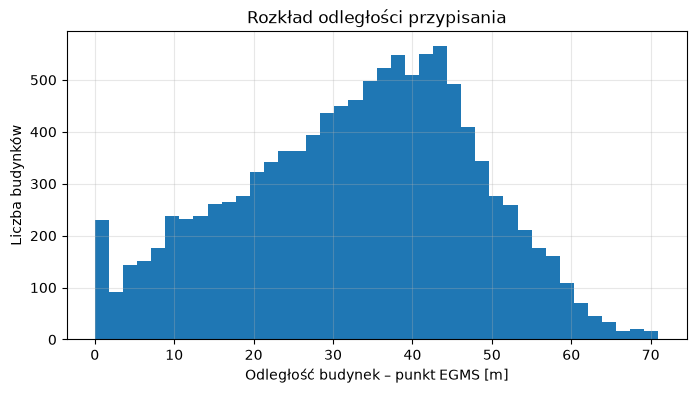

In [9]:
matched = buildings_ps["has_PS"]

print("Wszystkie budynki:", len(buildings_ps))
print(f"Budynki z PS do {MAX_DISTANCE} m:", matched.sum())
print(f"Budynki bez PS do {MAX_DISTANCE} m:", (~matched).sum())
print("Wykorzystane unikalne PS:", buildings_ps["pid"].nunique())
print(
    "Mediana odległości:",
    round(buildings_ps.loc[matched, "distance_PS"].median(), 1), "m"
)

plt.figure(figsize=(8, 4))
plt.hist(buildings_ps.loc[matched, "distance_PS"], bins=40)
plt.xlabel("Odległość budynek – punkt EGMS [m]")
plt.ylabel("Liczba budynków")
plt.title("Rozkład odległości przypisania")
plt.grid(alpha=0.3)
plt.show()

## Nazwy klastrów

Numery klastrów K-means zależą od inicjalizacji, dlatego nazwy nadajemy na podstawie mediany `mean_velocity` w klastrze, a nie samego numeru:

- najniższa mediana → **osiadanie po erupcji** (stabilne do 2021, potem silne osiadanie),
- najwyższa mediana → **wypiętrzenie 2021** (unoszenie przed erupcją i w jej trakcie, potem lekkie opadanie),
- pozostały → **stabilne**.

Opis wynika z median szeregów czasowych w klastrach (notebook 1) i powinien zostać potwierdzony na mapie.

In [10]:
cluster_velocity = ps.groupby("cluster")["mean_velocity"].median().sort_values()

cluster_names = {
    cluster_velocity.index[0]: "osiadanie po erupcji",
    cluster_velocity.index[-1]: "wypiętrzenie 2021",
}
for c in cluster_velocity.index[1:-1]:
    cluster_names[c] = "stabilne"

buildings_ps["cluster_name"] = buildings_ps["cluster"].map(cluster_names)
buildings_ps["anomaly_label"] = np.where(
    buildings_ps["has_PS"],
    np.where(buildings_ps["anomaly"] == True, "anomalny", "typowy"),
    "brak PS"
)

pd.DataFrame({
    "median_mean_velocity": cluster_velocity.round(2),
    "nazwa": pd.Series(cluster_names)
})

,median_mean_velocity,nazwa
0,-26.85,osiadanie po erupcji
1,-1.20,stabilne
2,12.80,wypiętrzenie 2021


## Budynki w klastrach i wśród anomalii

In [11]:
summary = (
    buildings_ps[buildings_ps["has_PS"]]
    .groupby("cluster_name")
    .agg(
        budynki=("building_id", "count"),
        unikalne_PS=("pid", "nunique"),
        budynki_anomalne=("anomaly", "sum"),
        mediana_v=("mean_velocity", "median"),
        mediana_trend_change=("trend_change", "median"),
    )
    .round(2)
)
summary["udzial_anomalnych_%"] = (
    summary["budynki_anomalne"] / summary["budynki"] * 100
).round(1)
summary

,budynki,unikalne_PS,budynki_anomalne,mediana_v,mediana_trend_change,udzial_anomalnych_%
cluster_name,,,,,,
osiadanie po erupcji,2275,500,1628,-28.4,-28.62,71.6
stabilne,7477,1556,10,-1.6,2.32,0.1
wypiętrzenie 2021,1511,334,1,12.2,-18.08,0.1


In [12]:
result = buildings[["building_id"] + building_attrs + ["geometry"]].merge(
    buildings_ps.drop(columns=["geometry", "index_right"], errors="ignore"),
    on="building_id",
    how="left"
)
result = gpd.GeoDataFrame(result, geometry="geometry", crs=buildings.crs)

pd.crosstab(
    result["type"].fillna("brak danych"),
    result["anomaly_label"],
    margins=True
)

anomaly_label,anomalny,brak PS,typowy,All
type,,,,
non-residential,212,199,1836,2247
residential,1427,273,7788,9488
All,1639,472,9624,11735


## Pole lawowe z 2021 r.

EUBUCCO opiera się na katastrze sprzed erupcji, więc zawiera też budynki, które lawa zniszczyła. Nakładamy końcowy zasięg lawy z Copernicus EMS (EMSR546, 17.12.2021) i dzielimy budynki na trzy strefy:

- **pod lawą** — centroid budynku leży w obrysie lawy (budynek zniszczony),
- **przy granicy** — budynek poza lawą, ale nie dalej niż 100 m od jej krawędzi (jedna komórka EGMS),
- **dalej** — pozostałe.

Sprawdzamy też, czy **sam punkt EGMS** przypisany do budynku leży na lawie. Taki punkt opisuje ruch powierzchni lawy (stygnięcie i kompakcja), a nie gruntu pod budynkiem.

In [13]:
lava = gpd.read_file("lawa/EMSR546_lava_2021-12-17.geojson").to_crs(buildings.crs)
lava_poly = lava.geometry.union_all()
print("Powierzchnia lawy:", round(lava_poly.area / 1e6, 2), "km²")

NEAR_LAVA = 100  # m

result["dist_lava"] = result.geometry.distance(lava_poly).round(1)
under_lava = result.geometry.centroid.within(lava_poly)

result["lava_zone"] = np.select(
    [under_lava, result["dist_lava"] <= NEAR_LAVA],
    ["pod lawą", "przy granicy"],
    default="dalej"
)

ps_on_lava = ps_gdf.loc[ps_gdf.within(lava_poly), "pid"]
result["ps_on_lava"] = result["pid"].isin(ps_on_lava)

print("PS na lawie:", len(ps_on_lava), "z", len(ps_gdf))
print("Anomalie na lawie:", ps_gdf.loc[ps_gdf["pid"].isin(ps_on_lava), "anomaly"].sum(),
      "z", ps_gdf["anomaly"].sum())
result["lava_zone"].value_counts()

Powierzchnia lawy: 12.4 km²


PS na lawie: 899 z 9155
Anomalie na lawie: 417 z 458


lava_zone
dalej           8231
pod lawą        2891
przy granicy     613
Name: count, dtype: int64

### Walidacja z oceną uszkodzeń Copernicus

Copernicus EMS oznaczył każdy budynek w rejonie erupcji jako *Destroyed*, *Possibly damaged* albo *No visible damage*. Punkty oceny przypisujemy do obrysów EUBUCCO (najbliższy budynek do 5 m) i porównujemy z naszą strefą.

In [14]:
damage = gpd.read_file("lawa/EMSR546_buildings_damage_2021-12-17.geojson").to_crs(buildings.crs)

damage_join = gpd.sjoin_nearest(
    damage[["damage_gra", "geometry"]],
    result[["building_id", "lava_zone", "geometry"]],
    how="inner",
    max_distance=5
)

print("Punkty oceny dopasowane do budynku:", damage_join["building_id"].nunique(), "/", len(damage))
pd.crosstab(damage_join["damage_gra"], damage_join["lava_zone"])

Punkty oceny dopasowane do budynku: 5804 / 8879


lava_zone,dalej,pod lawą,przy granicy
damage_gra,,,
Destroyed,0,2173,9
No visible damage,3797,2,182
Possibly damaged,0,2,111


### Prędkość osiadania a odległość od lawy

Mediana `mean_velocity` budynków poza lawą w kolejnych pasach odległości od krawędzi. Pokazuje, jak daleko od pola lawowego sięga osiadanie.

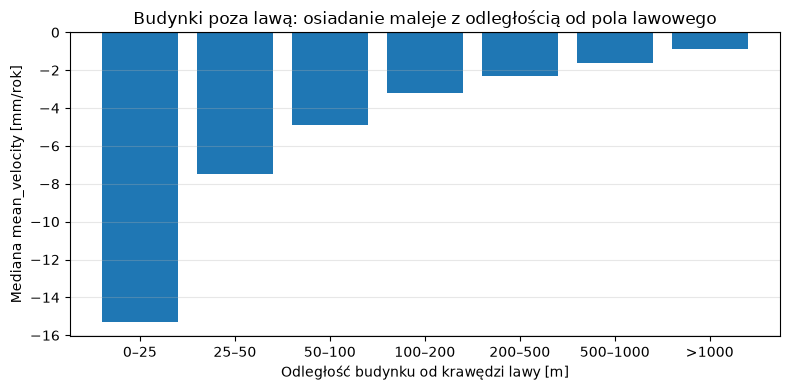

,budynki,mediana_v,osiadanie_ponad_10
dist_band,,,
0–25,176,-15.3,124
25–50,131,-7.5,50
50–100,178,-4.9,15
100–200,325,-3.2,11
200–500,603,-2.3,7
500–1000,1434,-1.6,0
>1000,5519,-0.9,0


In [15]:
bins = [0, 25, 50, 100, 200, 500, 1000, np.inf]
labels = ["0–25", "25–50", "50–100", "100–200", "200–500", "500–1000", ">1000"]

outside = result[(result["lava_zone"] != "pod lawą") & result["has_PS"] & ~result["ps_on_lava"]].copy()
outside["dist_band"] = pd.cut(outside["dist_lava"], bins=bins, labels=labels, include_lowest=True)

distance_profile = (
    outside.groupby("dist_band", observed=True)
    .agg(
        budynki=("building_id", "count"),
        mediana_v=("mean_velocity", "median"),
        osiadanie_ponad_10=("mean_velocity", lambda v: (v <= -10).sum()),
    )
    .round(2)
)

plt.figure(figsize=(8, 4))
plt.bar(distance_profile.index.astype(str), distance_profile["mediana_v"])
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Odległość budynku od krawędzi lawy [m]")
plt.ylabel("Mediana mean_velocity [mm/rok]")
plt.title("Budynki poza lawą: osiadanie maleje z odległością od pola lawowego")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("profil_odleglosc_od_lawy.png", dpi=200)
plt.show()

distance_profile

## Priorytet szczegółowej analizy

Prawie wszystkie anomalie Isolation Forest to punkty **na lawie**, czyli model wykrył przede wszystkim samo pole lawowe. Budynki pod lawą nie istnieją, więc nie ma czego monitorować. Priorytet liczymy tylko dla budynków, które przetrwały:

| Priorytet | Warunek |
| --- | --- |
| zniszczony | budynek pod lawą (wyłączony z listy) |
| **1 — wysoki** | punkt EGMS poza lawą **i** (osiadanie szybsze niż 10 mm/rok **albo** punkt anomalny) |
| **2 — średni** | punkt EGMS leży na lawie (sygnał niepewny, sprawdzić w terenie) **albo** budynek przy granicy z osiadaniem szybszym niż 5 mm/rok **albo** klaster „osiadanie po erupcji” |
| **3 — niski** | pozostałe budynki z punktem EGMS |
| brak danych | brak punktu w promieniu 71 m |

Progi 10 i 5 mm/rok są umowne. W obrębie priorytetu sortujemy od najszybszego osiadania.

In [16]:
SUBSIDENCE_HIGH = -10  # mm/rok
SUBSIDENCE_MEDIUM = -5  # mm/rok

destroyed = result["lava_zone"] == "pod lawą"
has_ps = result["has_PS"] == True
is_anomaly = result["anomaly"] == True
v = result["mean_velocity"]

result["priority"] = np.select(
    [
        destroyed,
        has_ps & ~result["ps_on_lava"] & ((v <= SUBSIDENCE_HIGH) | is_anomaly),
        has_ps & (
            result["ps_on_lava"]
            | ((result["lava_zone"] == "przy granicy") & (v <= SUBSIDENCE_MEDIUM))
            | (result["cluster_name"] == "osiadanie po erupcji")
        ),
        has_ps,
    ],
    [-1, 1, 2, 3],
    default=0
)
result["priority_label"] = result["priority"].map({
    -1: "zniszczony (pod lawą)", 1: "1 - wysoki", 2: "2 - średni", 3: "3 - niski", 0: "brak danych"
})

pd.crosstab(result["priority_label"], result["lava_zone"], margins=True)

lava_zone,dalej,pod lawą,przy granicy,All
priority_label,,,,
1 - wysoki,19,0,189,208
2 - średni,0,0,274,274
3 - niski,7862,0,146,8008
brak danych,350,0,4,354
zniszczony (pod lawą),0,2891,0,2891
All,8231,2891,613,11735


## Lista budynków do szczegółowej analizy

Wiele budynków dzieli ten sam punkt EGMS (komórka 100 m), dlatego oprócz listy budynków pokazujemy też, ile **różnych punktów** stoi za priorytetem 1.

In [17]:
centroids = result.geometry.centroid.to_crs("EPSG:4326")
result["lon"] = centroids.x.round(5)
result["lat"] = centroids.y.round(5)

list_cols = [
    "building_id", "id", "type", "subtype", "floors", "const_yr",
    "lat", "lon", "pid", "distance_PS",
    "mean_velocity", "acceleration", "trend_change", "anomaly_score",
    "cluster_name", "lava_zone", "dist_lava", "ps_on_lava", "priority_label"
]

to_analyse = (
    result[result["priority"].isin([1, 2])]
    .sort_values(["priority", "mean_velocity"], ascending=[True, True])
    [list_cols]
    .reset_index(drop=True)
)

print("Budynki z priorytetem 1:", (to_analyse["priority_label"] == "1 - wysoki").sum())
print("Budynki z priorytetem 2:", (to_analyse["priority_label"] == "2 - średni").sum())
print("Różne PS za priorytetem 1:",
      to_analyse.loc[to_analyse["priority_label"] == "1 - wysoki", "pid"].nunique())

to_analyse.head(20).round(2)

Budynki z priorytetem 1: 208
Budynki z priorytetem 2: 274
Różne PS za priorytetem 1: 61


,building_id,id,type,subtype,floors,const_yr,lat,lon,pid,distance_PS,mean_velocity,acceleration,trend_change,anomaly_score,cluster_name,lava_zone,dist_lava,ps_on_lava,priority_label
0,3314,4b276d5bc47842bb-0,residential,detached,2.0,2009.0,28.62,-17.91,40DeMS4BBz,28.53,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,0.0,False,1 - wysoki
1,3701,5b50121ec817471a-0,residential,detached,1.0,2011.0,28.62,-17.91,40DeMS4BBz,24.54,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,4.6,False,1 - wysoki
2,4722,8b402c0a6d26426c-0,residential,detached,1.0,2003.0,28.62,-17.91,40DeMS4BBz,21.32,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,0.0,False,1 - wysoki
3,6127,d00b218d01ed443c-0,residential,detached,1.0,1997.0,28.62,-17.91,40DeMS4BBz,21.22,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,3.6,False,1 - wysoki
4,6765,ebc83cec9ca14d5a-0,residential,detached,1.0,1997.0,28.62,-17.91,40DeMS4BBz,43.09,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,8.4,False,1 - wysoki
5,6805,ed688d960b1e4a7e-0,residential,detached,1.0,1997.0,28.62,-17.91,40DeMS4BBz,33.60,-27.5,-15.83,-6.75,0.61,osiadanie po erupcji,przy granicy,9.3,False,1 - wysoki
6,1695,02a4a4a6e7bf4d57-0,residential,detached,1.0,2011.0,28.62,-17.91,40DeaW3umD,6.16,-25.5,-15.62,-6.34,0.61,osiadanie po erupcji,przy granicy,5.3,False,1 - wysoki
7,1977,0fd57287bbb046e3-0,residential,detached,1.0,2007.0,28.62,-17.91,40DeaW3umD,4.08,-25.5,-15.62,-6.34,0.61,osiadanie po erupcji,przy granicy,0.0,False,1 - wysoki
8,1978,0fd57287bbb046e3-1,residential,detached,2.0,2003.0,28.62,-17.91,40DeaW3umD,20.46,-25.5,-15.62,-6.34,0.61,osiadanie po erupcji,przy granicy,0.0,False,1 - wysoki
9,1979,0fd57287bbb046e3-2,residential,detached,1.0,2011.0,28.62,-17.91,40DeaW3umD,7.89,-25.5,-15.62,-6.34,0.61,osiadanie po erupcji,przy granicy,0.0,False,1 - wysoki


### Punkty EGMS z największą liczbą zagrożonych budynków

Ta tabela jest wygodniejsza do prezentacji niż lista tysięcy budynków: jeden wiersz to jedna komórka 100 m.

In [18]:
ps_priority = (
    result[result["priority"] == 1]
    .groupby("pid")
    .agg(
        budynki=("building_id", "count"),
        mieszkalne=("type", lambda s: (s == "residential").sum()),
        lat=("lat", "median"),
        lon=("lon", "median"),
        mean_velocity=("mean_velocity", "first"),
        trend_change=("trend_change", "first"),
        anomaly_score=("anomaly_score", "first"),
        cluster_name=("cluster_name", "first"),
        min_dist_lava=("dist_lava", "min"),
    )
    .sort_values(["mean_velocity", "budynki"], ascending=[True, False])
    .round(3)
)
ps_priority.head(15)

,budynki,mieszkalne,lat,lon,mean_velocity,trend_change,anomaly_score,cluster_name,min_dist_lava
pid,,,,,,,,,
40DeMS4BBz,6,6,28.619,-17.911,-27.5,-6.753,0.615,osiadanie po erupcji,0.0
40DeaW3umD,5,5,28.623,-17.909,-25.5,-6.340,0.613,osiadanie po erupcji,0.0
40DdpdPSq1,1,1,28.624,-17.880,-25.2,-27.907,0.614,osiadanie po erupcji,71.5
40DeMS4BBy,3,3,28.620,-17.911,-24.6,-3.629,0.595,osiadanie po erupcji,2.5
40DdgG4yRy,1,1,28.623,-17.874,-24.6,-14.842,0.586,osiadanie po erupcji,30.0
40DdgG4yRz,6,6,28.623,-17.873,-23.3,-7.621,0.579,osiadanie po erupcji,15.2
40DdkwkDe0,2,2,28.624,-17.876,-23.2,-18.924,0.582,osiadanie po erupcji,57.8
40Ddz0jxE7,1,0,28.625,-17.882,-23.1,-29.578,0.621,osiadanie po erupcji,1.2
40DdNVPzf8,10,10,28.608,-17.907,-22.6,1.169,0.579,stabilne,0.2


## Mapa: priorytety budynków i pole lawowe

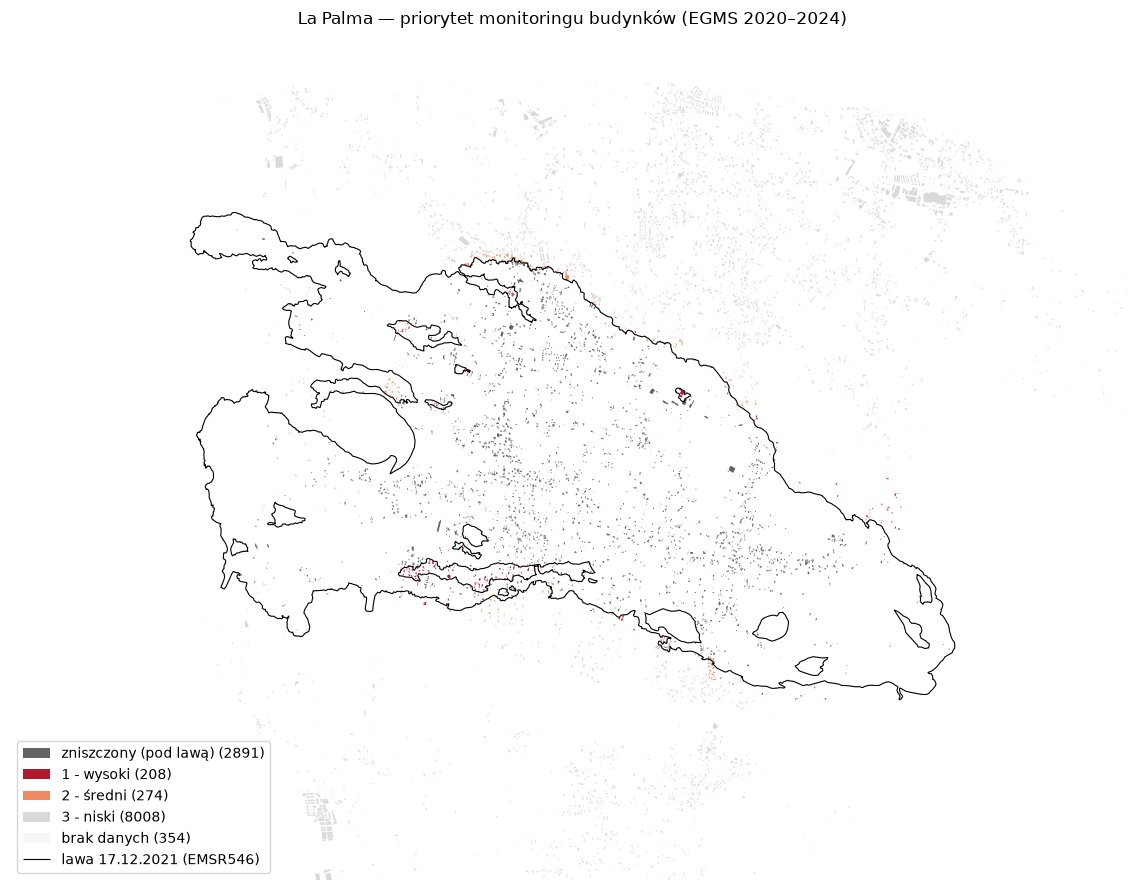

In [19]:
priority_colors = {
    "zniszczony (pod lawą)": "#636363",
    "1 - wysoki": "#b2182b",
    "2 - średni": "#ef8a62",
    "3 - niski": "#d9d9d9",
    "brak danych": "#f7f7f7",
}

# Kadrujemy mapę na rejon pola lawowego, bo tam są wszystkie budynki z priorytetem 1 i 2
xmin, ymin, xmax, ymax = lava_poly.buffer(1500).bounds

fig, ax = plt.subplots(figsize=(12, 9))
for name, color in priority_colors.items():
    subset = result[result["priority_label"] == name]
    if len(subset):
        subset.plot(ax=ax, color=color, linewidth=0, label=f"{name} ({len(subset)})")

lava.boundary.plot(ax=ax, color="black", linewidth=0.8, label="lawa 17.12.2021 (EMSR546)")

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("La Palma — priorytet monitoringu budynków (EGMS 2020–2024)")
ax.set_axis_off()
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig("mapa_budynki_priorytet.png", dpi=200)
plt.show()

## Kontrola: szeregi czasowe punktów z priorytetem 1

Wykresy wymagają pliku `punkty_cleaned.csv` z pełnymi szeregami (nie ma go w repozytorium). Przerywane linie oznaczają początek i koniec erupcji.

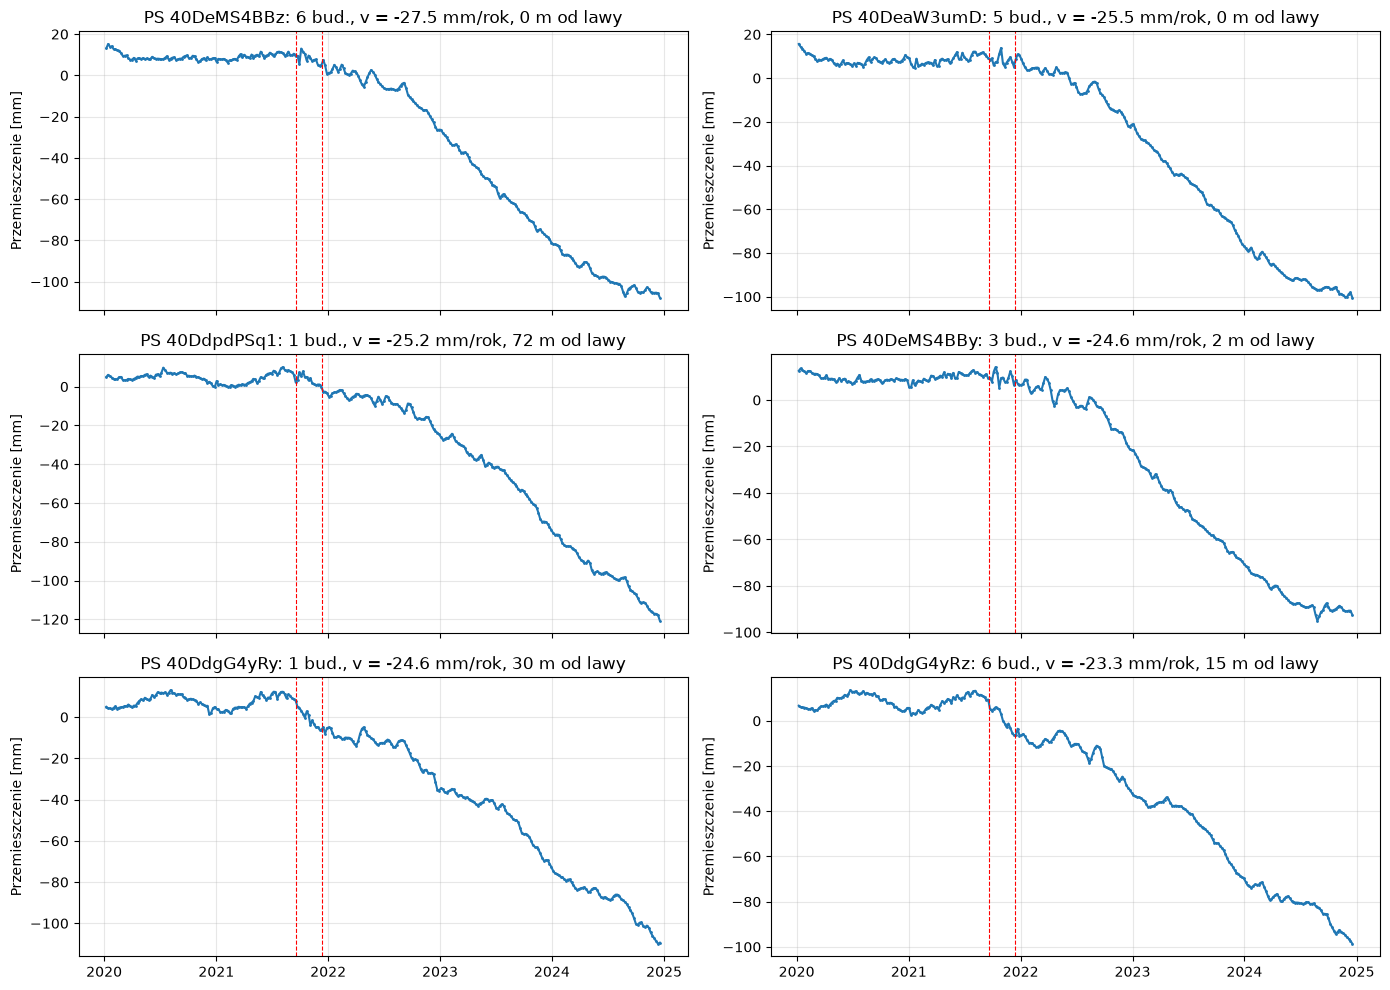

In [20]:
ts_path = Path("punkty_cleaned.csv")
if not ts_path.exists():
    ts_path = Path("..") / "punkty_cleaned.csv"

if ts_path.exists():
    top_pids = ps_priority.head(6).index.tolist()
    ts = pd.read_csv(ts_path)
    ts = ts[ts["pid"].isin(top_pids)].set_index("pid")
    date_cols = [c for c in ts.columns if c.isdigit() and len(c) == 8]
    dates = pd.to_datetime(date_cols, format="%Y%m%d")

    fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
    for ax, pid in zip(axes.flatten(), top_pids):
        ax.plot(dates, ts.loc[pid, date_cols].astype(float).values, marker=".", markersize=2)
        for d in ["2021-09-19", "2021-12-13"]:
            ax.axvline(pd.Timestamp(d), color="red", linestyle="--", linewidth=0.8)
        info = ps_priority.loc[pid]
        ax.set_title(
            f"PS {pid}: {int(info['budynki'])} bud., v = {info['mean_velocity']:.1f} mm/rok, "
            f"{info['min_dist_lava']:.0f} m od lawy"
        )
        ax.set_ylabel("Przemieszczenie [mm]")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("szeregi_priorytet1.png", dpi=200)
    plt.show()
else:
    print("Brak punkty_cleaned.csv — pomijam wykresy szeregów.")

## Eksport wyników

In [21]:
result.drop(columns=["lon", "lat"]).to_file(
    "budynki_LaPalma_results.gpkg",
    layer="budynki_EGMS",
    driver="GPKG"
)
to_analyse.to_csv("budynki_do_analizy.csv", index=False)
ps_priority.to_csv("punkty_priorytet1.csv")

lava.to_file("budynki_LaPalma_results.gpkg", layer="lawa_EMSR546", driver="GPKG")

print("Zapisano: budynki_LaPalma_results.gpkg (warstwy budynki_EGMS, lawa_EMSR546), "
      "budynki_do_analizy.csv, punkty_priorytet1.csv")

Zapisano: budynki_LaPalma_results.gpkg (warstwy budynki_EGMS, lawa_EMSR546), budynki_do_analizy.csv, punkty_priorytet1.csv
